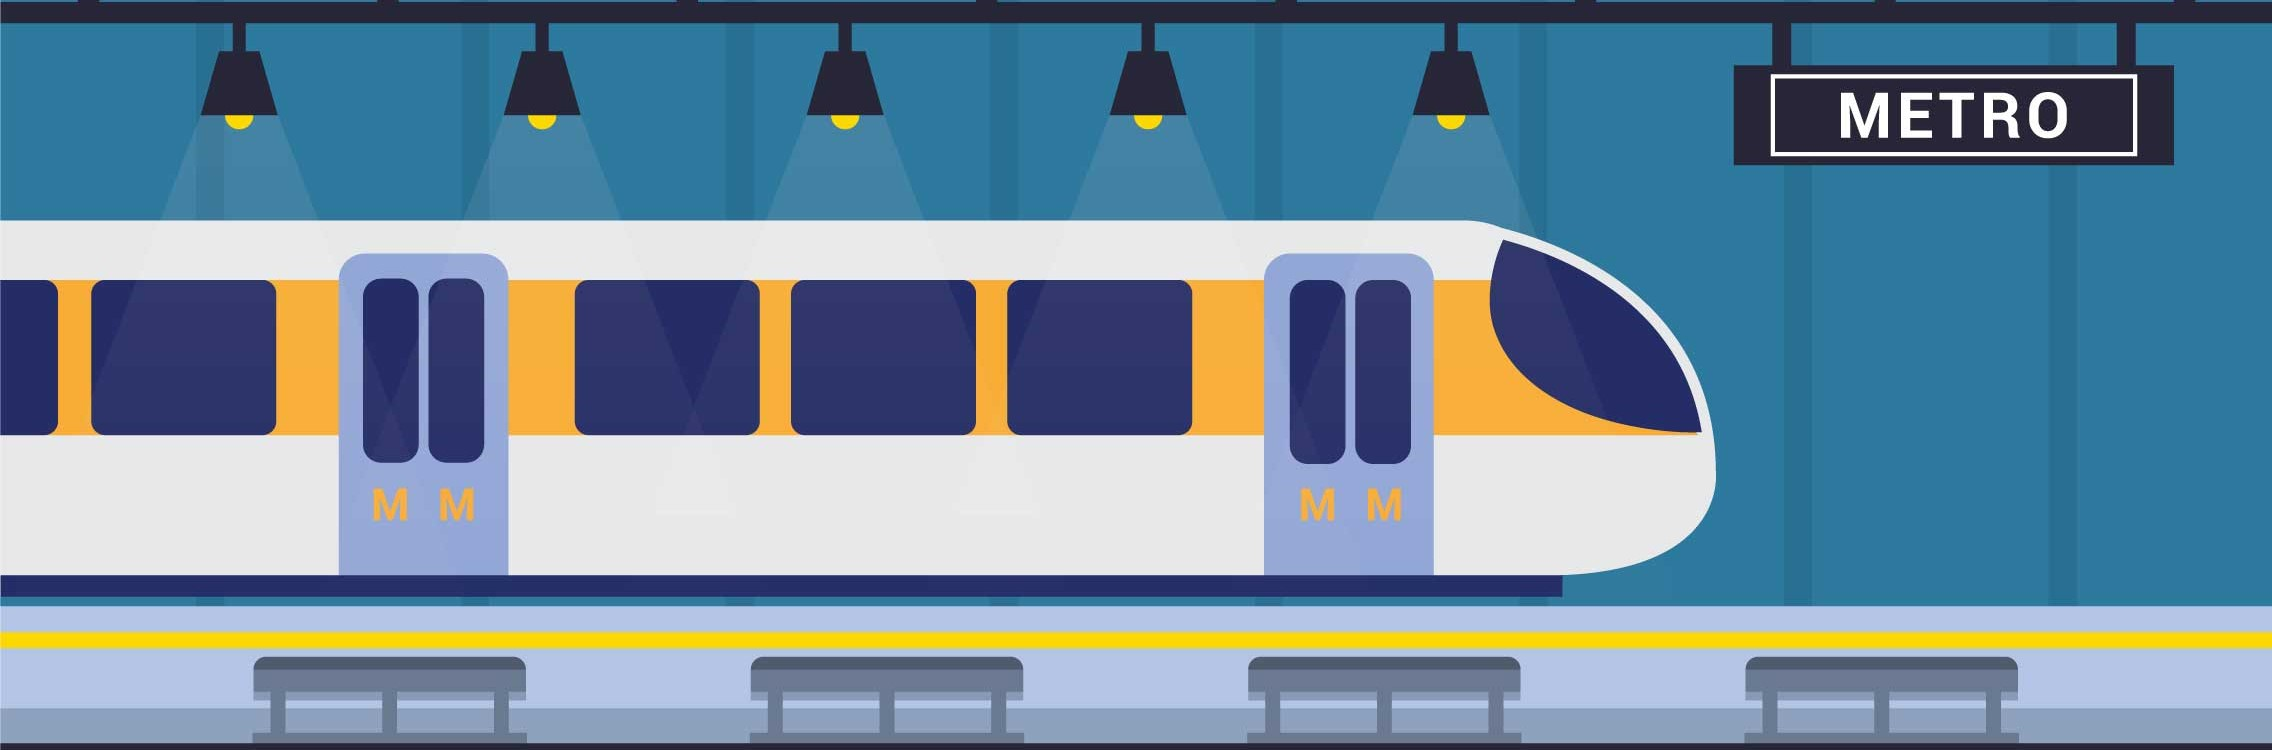

🚀 Unleash your inner data explorer! Welcome to a comprehensive dataset designed to turbocharge your data analysis, datatype mastery, and data interpretation skills! 🌟 Get ready for a thrilling journey of insights and discoveries! 🧨📊 

👨‍💻 **Practice Time:** Don't forget to challenge yourself with the added practice questions! Test your skills and dive even deeper into the world of data. 🚀💡 

**#DataAdventureBegins**

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/chennai-metro-dataset/chennai_metro_rail_limited_chennai.csv


# 📚 Importing Libraries

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns # for visualization
import matplotlib.pyplot as plt

# 👁 Reading Datafile

In [3]:
df = pd.read_csv('/kaggle/input/chennai-metro-dataset/chennai_metro_rail_limited_chennai.csv')

# 🥽 Exploring data

In [4]:
df.shape

(34, 7)

Ah, a compact dataset indeed! With just 34 rows and 7 columns, it's the kind of dataset we often encounter in our classroom lessons, where each column represents a variable. A perfect size for hands-on learning and practicing data analysis techniques. Ready to unlock insights from this petite but powerful dataset! 📊🔍

In [5]:
df.head()

,City,Zone,Division,Corridor Name,Interchange,Station Name,Layout
0,Chennai,12,159,Corridor 1 Green Line,Sub Urban South Line,Chennai Airport,Elevated
1,Chennai,12,159,Corridor 1 Green Line,No,Meenambakkam,Elevated
2,Chennai,Cantonment,Cantonment,Corridor 1 Green Line,No,Nanganallur road,Elevated
3,Chennai,Cantonment,Cantonment,Corridor 1 Green Line,CMRL Blue line,Alandur,Elevated
4,Chennai,12,160,Corridor 1 Green Line,Sub Urban South Line,Gindy,Elevated


Alternatively try **df.tail()** and **df.sample()** and see how it works.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   City           34 non-null     object
 1   Zone           34 non-null     object
 2   Division       34 non-null     object
 3   Corridor Name  34 non-null     object
 4   Interchange    34 non-null     object
 5   Station Name   34 non-null     object
 6   Layout         34 non-null     object
dtypes: object(7)
memory usage: 2.0+ KB


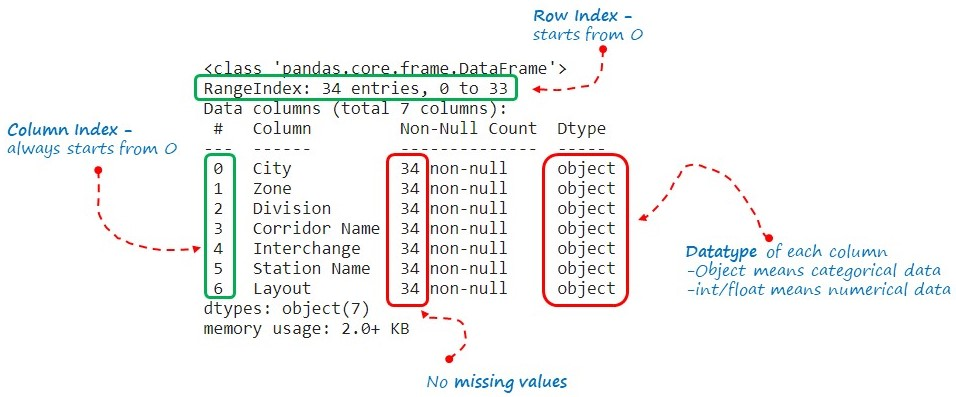

Checking for null values is a must-do. We often use the `isna()` function, but remember, if nulls are marked with symbols like '?', '.', 'NA', 'no', 'nil', the function might not catch them. It sees these as regular strings, not nulls.

Always a smart move is to sync up with the data owner and find out how they mark null entries. It's like having a secret code for handling missing data! 🕵️‍♂️💻 #DataCleaningWisdom


In [7]:
df.isna().sum()

City             0
Zone             0
Division         0
Corridor Name    0
Interchange      0
Station Name     0
Layout           0
dtype: int64

Its our Lucky day! we have no missing data in our dataset and our dataowner confirmed no unconventional markers are used for null values

In [8]:
df.describe()

,City,Zone,Division,Corridor Name,Interchange,Station Name,Layout
count,34,34,34,34,34,34,34
unique,1,7,25,2,7,33,2
top,Chennai,5,58,Corridor 1 Green Line,No,Alandur,Underground
freq,34,8,3,17,26,2,20


describe() function automatically identifies the datatype and with suitable descriptive statistics provides valuable insights into the distribution and characteristics of the data

1. **Count:** The total number of observations in the dataset for a specific categorical variable.

2. **Unique:** The number of distinct categories present in the dataset for a particular variable.

3. **Top:** The most frequently occurring category in the dataset for a specific variable.

4. **Freq:** The count of the top category, i.e., the number of times the top category appears in the dataset.

In [9]:
#Unique: The number of distinct categories present in the dataset for a particular variable
df.nunique()

City              1
Zone              7
Division         25
Corridor Name     2
Interchange       7
Station Name     33
Layout            2
dtype: int64

# Exploring each column one at a time

# 1️⃣ City

In [10]:
#describe function works for single column as well
df['City'].describe()

count          34
unique          1
top       Chennai
freq           34
Name: City, dtype: object

In [11]:
# Print unique values in the 'City' column
print(df['City'].unique())

['Chennai']


A categorical variable with only one unique value is often considered uninformative for analytics due to its lack of variance. Since there is no variation in the data, it provides no discriminatory power or insights for analysis. 

How to handle them?

- excluding or addressing it depending on the dataset

In our case we can drop ✂ the column as it doesn't add any value.

In [12]:
df = df.drop('City',axis=1)

In [13]:
df.shape

(34, 6)

# 2️⃣ Station Name

In [14]:
df['Station Name'].describe()

count          34
unique         33
top       Alandur
freq            2
Name: Station Name, dtype: object

If you observe the unique values, ideally, each station should be unique. However, in our dataset, there is one instance of a duplicate station name.

In [15]:
df['Station Name'].value_counts()

Station Name
Alandur                  2
Chennai Airport          1
Anna Nagar Tower         1
Ashok Nagar KK Nagar     1
Vadapalani               1
Arumbakkam               1
CMBT                     1
Koyembedu                1
Thirumangalam            1
Anna Nagar East          1
St Thomas Mount          1
Shenoy Nagar             1
Pachaiyappa's College    1
Kilpauk                  1
Nehru Fark               1
Egmore                   1
Ekkattuthanqal           1
Washermenpet             1
Meenambakkam             1
Manadi                   1
Highcourt                1
Chennai Central          1
Government Estate        1
LIC                      1
Thousand Lights          1
AG-DMS                   1
Teynampet                1
Nandanam                 1
Saidapet                 1
Liltle mount             1
Gindy                    1
Nanganallur road         1
Central Metro            1
Name: count, dtype: int64

In [16]:
df[df['Station Name'] == 'Alandur']

,Zone,Division,Corridor Name,Interchange,Station Name,Layout
3,Cantonment,Cantonment,Corridor 1 Green Line,CMRL Blue line,Alandur,Elevated
18,Cantonment,Cantonment,Corridor 2 Blue line,CMRL Green Line,Alandur,Elevated


Ahaa! When encountering duplicates, the immediate instinct might be to remove them. 
However, it's not the time for that. Let's take a closer look at our data and unravel the mystery surrounding the 'Alandur' station before deciding the best course of action. 🕵️‍♂️🔍 #DataMysteryInProgress

# 3️⃣ Zone

In [17]:
df['Zone'].describe()

count     34
unique     7
top        5
freq       8
Name: Zone, dtype: object

In [18]:
# Print unique values in the 'City' column
print(df['Zone'].unique())

['12' 'Cantonment' '13' '9' '5' '10' '8']


Oops, we have both numbers and strings. Why and how should we treat it, as numerical or categrical?😲

To answer why first we need to understand the data 'zone'. 'zone' is nothing but a unique code assigned to a specific region. Although the values are represented numerically, the numerical codes assigned to each region (zone) are identifiers rather than inherently meaningful numerical quantities. In other words, the numeric values lack a meaningful order or magnitude; they are simply labels or codes to uniquely identify different regions.

 Therefore we need to treat "zone" as a categorical column due to the nature of the data

In [19]:
df['Zone'].value_counts()

Zone
5             8
8             8
12            4
9             4
10            4
Cantonment    3
13            3
Name: count, dtype: int64

Did you see when we called decribe(), we got only "zone 5" as top freq, but we also have "zone 8". why didn't it show?🙄


The reason only "zone 5" is reported as the top frequency in the **describe() function**, despite the presence of "zone 8," can be explained by the fact that the describe() function is designed to provide descriptive statistics **primarily for numeric data**. In the case of categorical data, it may not accurately capture the full range of information(Just like in our case, it missed 'zone 8').

Text(0.5, 1.0, 'No of stations by zone')

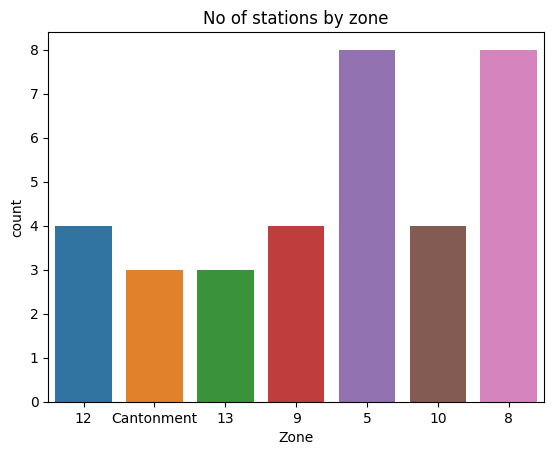

In [20]:
sns.countplot(data=df, x='Zone')
plt.title('No of stations by zone')

Using visualizations helped us quickly see the top categories as Zone 5 and 8. 

# 🤸‍♀️ Practice exercise 1 

1. Identify unique values in division
1. Identify the datatype of division
1. Find the zone most division using chartsIdentify unique values in division

In [21]:
#Identify unique values in division

In [22]:
#Identify the datatype of division

In [23]:
#Find the zone most division using chartsIdentify unique values in division

# 4️⃣ Corridor Name

In [24]:
df['Corridor Name'].unique()

array(['Corridor 1 Green Line', 'Corridor 2 Blue line'], dtype=object)

In [25]:
df['Corridor Name'].value_counts()

Corridor Name
Corridor 1 Green Line    17
Corridor 2 Blue line     17
Name: count, dtype: int64

We used countplot from seaborn in the last example, let see if we can use different plot to acheive the same

Text(0.5, 1.0, 'No of stations in each metrolines')

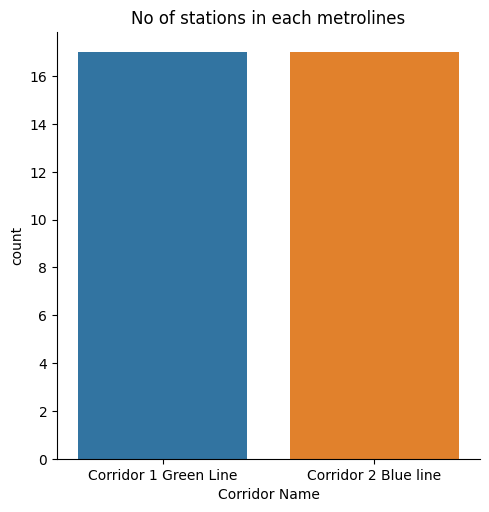

In [26]:
sns.catplot(data=df,x='Corridor Name',kind='count')

plt.title('No of stations in each metrolines')

Note! It's important to highlight that our graph may not be entirely reliable at this stage, given the unresolved mystery around the duplicate entry for the 'Álandur' station. We'll circle back to address this question as we progress. For now, let's stay focused on the exciting world of graphing! 📊✨

Text(0.5, 1.0, 'No of stations in zones with their metrolines')

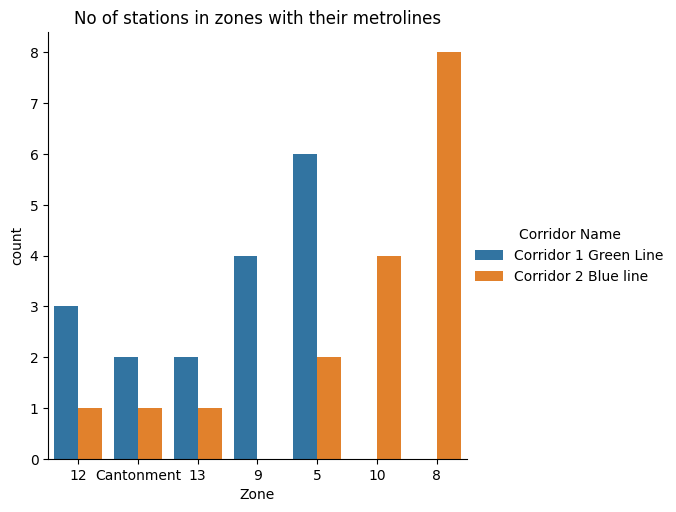

In [27]:
sns.catplot(data=df,x='Zone',kind='count',hue='Corridor Name')

plt.title('No of stations in zones with their metrolines')

We can easily look at no of stations in each lines side by side as well. Additionally, it is a good idea to keep data clean and easy to read. 

Therefore instead of 'Corridor 2 Blue line' & 'Corridor 1 Blue Line', let us shorten them!

In [28]:
df['Metro Line'] = np.where(df['Corridor Name'] == 'Corridor 2 Blue line', 'Blue', 'Green')

In [29]:
df['Metro Line'].value_counts()

Metro Line
Green    17
Blue     17
Name: count, dtype: int64

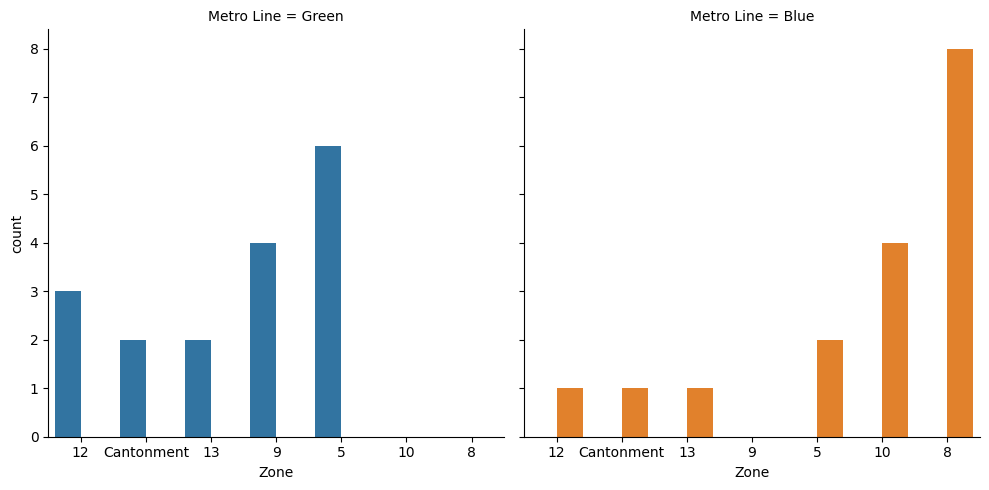

In [30]:
sns.catplot(data=df,x='Zone',kind='count',hue='Metro Line',col='Metro Line')

Excellent observation! Zones 9, 8, and 10 stand out on the graph as they seem to have only one line connecting all their stations. This sparks curiosity and opens the door to intriguing questions – why is this the case?

Let's dive deeper into additional variables to unravel the answers we seek. The journey of exploration continues! 🕵️‍♂️🚇 #CuriousDataAnalysis


# 5️⃣ Interchange

In [31]:
df['Interchange'].unique()

array(['Sub Urban South Line', 'No', 'CMRL Blue line',
       'Sub-Urban South Line,North Line, West Line, MRTS Line: CMRL Blue line',
       'CMRL Green Line', 'Sub Urban South Line ',
       'Sub Urban South Line; North Line; West Line; MRTS Line CMRL Green line'],
      dtype=object)

In [32]:
df['Interchange'].value_counts()

Interchange
No                                                                        26
Sub Urban South Line                                                       3
CMRL Blue line                                                             1
Sub-Urban South Line,North Line, West Line, MRTS Line: CMRL Blue line      1
CMRL Green Line                                                            1
Sub Urban South Line                                                       1
Sub Urban South Line; North Line; West Line; MRTS Line CMRL Green line     1
Name: count, dtype: int64

⁉ We saw earlier chennai metro has only two lines - Green and Blue. So ideally interchange can be between either green or blue line. However our dataset says otherwise. We got to see multiple other new terms. 

Ufff, we got a bad dataset variable! Isn't it?

⚠ Not really! before jumping to any conclusions always approach dataowners or subject matter experts to understand the data.This is natural, it not like always we get entire information of our variables from our dataset's meta data or description. Whenever a clarification on data is required don't hesitate to approach the dataowners.

Back to our question, luckily our dataowner have the answer- 

Chennai city has two different types of rail commutes based on how they operate. But the main difference between the two is that the metro trains are designed to be driven over independent rail lines, unlike suburban local trains that are forced to share paths with trains that are meant for covering long distances.

> Chennai city mainly has **four** **suburban** **railway** **lines** other than metrolines. These are the North Line, West Line, South Line and MRTS Line.

1. The North Line runs from the Chennai Central MMC to Bitragunta in Andhra Pradesh. Its suburban services end at Sullurpeta.

1. The West Line runs from MGR Chennai Central to Jolarpettai. Its suburban services end at Arakkonam.

1. The South Line starts from Chennai Beach and covers various stations to reach Puducherry, the last station. Its suburban services end at Chengalputtu.

1. MRTS line runs on an elevated track and covers the Chennai Beach to Velachery route. It provides the suburban service only.

Our dataset is primarily on CMRL (Chennai Metro) which has stations connecting to sub urban railway stations as well for the convenince of passengers. Isn't that fantasic! Even if our destination has only been connected by suburban line, we can still board our nearby metroline stations and switch to suburban trains through Interchange stations.


In [33]:
#Filtering stations that has Interchange connectivity

df[df['Interchange'] != 'No']

,Zone,Division,Corridor Name,Interchange,Station Name,Layout,Metro Line
0,12,159,Corridor 1 Green Line,Sub Urban South Line,Chennai Airport,Elevated,Green
3,Cantonment,Cantonment,Corridor 1 Green Line,CMRL Blue line,Alandur,Elevated,Green
4,12,160,Corridor 1 Green Line,Sub Urban South Line,Gindy,Elevated,Green
13,5,58,Corridor 1 Green Line,"Sub-Urban South Line,North Line, West Line, MR...",Chennai Central,Underground,Green
17,12,162,Corridor 2 Blue line,Sub Urban South Line,St Thomas Mount,Elevated,Blue
18,Cantonment,Cantonment,Corridor 2 Blue line,CMRL Green Line,Alandur,Elevated,Blue
32,5,58,Corridor 2 Blue line,Sub Urban South Line,Egmore,Underground,Blue
33,5,58,Corridor 2 Blue line,Sub Urban South Line; North Line; West Line; M...,Central Metro,Underground,Blue


Let's double-check our comprehension before moving forward!

Imagine a traveler arrives at Chennai Airport and intends to reach his home, which is connected by a suburban south railway line. How should they proceed?

If your initial thought was to advise them to take the metro from 'Chennai Airport' and transfer to a suburban train at an interchange station, we need to reconsider.

In reality, someone close to Chennai Airport can directly board the suburban train; there's no necessity to take the metro. 

Although the Interchange data explains how anyone travelling in metro trains can switch to other lines from specific stations and commute. We can derive additional information as well for example, from this we can say chennai airport has two local commute options -  metro and a suburban train.

Such manipulation of data ensures a more accurate understanding of the transportation options available, aligning our response with the insights provided by the dataset.

In [34]:
#Find no of stations with interageabilty and no_interchage facility

df['Interchange_availability'] = np.where(df['Interchange'] == 'No', 0, 1)
df.head(2)

,Zone,Division,Corridor Name,Interchange,Station Name,Layout,Metro Line,Interchange_availability
0,12,159,Corridor 1 Green Line,Sub Urban South Line,Chennai Airport,Elevated,Green,1
1,12,159,Corridor 1 Green Line,No,Meenambakkam,Elevated,Green,0


"Why did I use numbers to indicate Interchange? Is this a good idea for a categorical feature?"

It's a reasonable choice, especially if you intend to use the data for a machine learning model. Converting categorical data to numerical format is a crucial step, often accomplished through techniques like '*One-Hot Encoding*.' However, let's defer this discussion for another day when we delve deeper into machine learning.

Text(0.5, 1.0, 'No of stations with interchangability')

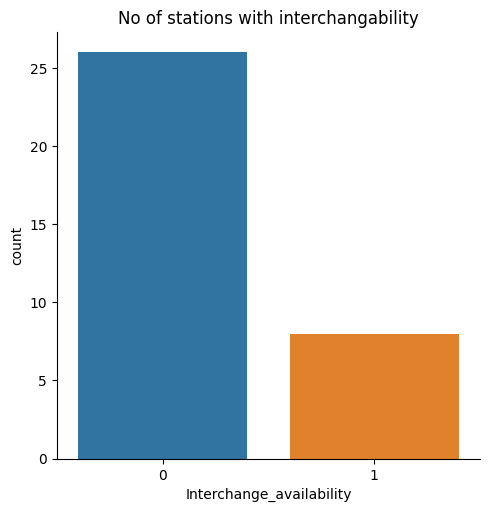

In [35]:
sns.catplot(data=df,x='Interchange_availability', kind='count')

plt.title('No of stations with interchangability')

We can see from the graph that 8 out of 34 stations offers train interachange option. Is my observation correct? or Is my graph accurate? 

It's time 🥁 to put the accuracy of our graph to the test!!

In [36]:
#Filtering the interchange stations and finding duplicate stations

df[df['Interchange_availability'] == 1]['Station Name'].value_counts()

Station Name
Alandur            2
Chennai Airport    1
Gindy              1
Chennai Central    1
St Thomas Mount    1
Egmore             1
Central Metro      1
Name: count, dtype: int64

In [37]:
df[df['Station Name'] == 'Alandur']


,Zone,Division,Corridor Name,Interchange,Station Name,Layout,Metro Line,Interchange_availability
3,Cantonment,Cantonment,Corridor 1 Green Line,CMRL Blue line,Alandur,Elevated,Green,1
18,Cantonment,Cantonment,Corridor 2 Blue line,CMRL Green Line,Alandur,Elevated,Blue,1


Bingo! Interchage variable is the key player in this data mystery. It turns out, it's the 'Alandur' station where you can smoothly hop between the Green and Blue metro lines. That's why we spotted two data points for Alandur – it's connected to both lines.

So, before we think about ditching any duplicates, always double-check if there's a story behind them. In this case, Alandur's double entry is intentional, shedding light on its role as a hub for switching lines. Understanding the meaning is the golden rule before deciding to remove any duplicates.

# 🤸‍♂️ Practice Question 2 

1. Answer how many unique stations are interchange stations through a bar graph 
1. Identify the no of station that connects to Suburban west line
1. A traveller is nearby Egmore and want to catch flight from Chennai Airport. What options do you recommend?
1. A passenger boarded from one of the zone 9 station and he got need to reach 'CMBT'. Does he need to switch lines. If yes, identify all possible routes


In [38]:
#Answer how many unique stations are interchange stations through a bar graph 

In [39]:
#Identify the no of station that connects to Suburban west line


In [40]:
#A traveller is nearby Egmore and want to catch flight from Chennai Airport. What options do you recommend?


In [41]:
#A passenger boarded from one of the zone 9 station and he got need to reach 'CMBT'. Does he need to switch lines. If yes, identify all possible routes

# Thank you detective!

In this little dataset adventure, we played detective like Sherlock Holmes, digging deep to discover hidden stories. Though the dataset is small, we found lots of interesting insights.

As we wrap up, remember that exploring data is like solving mysteries – there's always more to discover in the next case. 🕵️‍♂️🔍 If you found this notebook helpful, give it a thumbs up! Your support keeps the detective spirit alive. 👍

Don't miss the practice exercises – test your skills and uncover more intriguing insights! 🔍💻

Happy Exploring!

MMI 🚀🔍